# 🪔 Diwali Sales Analysis — Exploratory Data Analysis (EDA)

**Subject:** Data Science  |  **Course:** BCA (AI & Data Science), K.R. Mangalam University
**Submitted by:** Aarush Tyagi  |  **Roll No:** 2501201019  |  **Section:** A
**Dataset:** Diwali Sales Data (customer-level festive-season purchase records)

---
### 📑 Table of Contents
1. Title
2. Introduction
3. Tools Used
4. Working Methods (Methodology)
5. Working Module — EDA
   - 5.1 Importing Libraries
   - 5.2 Data Loading
   - 5.3 Data Understanding
   - 5.4 Data Cleaning
   - 5.5 Univariate Analysis
   - 5.6 Bivariate & Multivariate Analysis
   - 5.7 Advanced Visualisations (Heatmaps, Matrices, Box/Violin, Pareto, Bubble, Pairplot)
6. Use Case
7. Final Output (Key Findings, Executive Dashboard & Recommendations)
8. Conclusion

## 2. Introduction

Diwali, the festival of lights, is the **biggest shopping season in India**. Retailers see a huge spike in
sales of clothing, food, electronics, home décor and gifts. Understanding *who* buys, *what* they buy,
*where* they live and *how much* they spend helps a business plan stock, marketing and discounts.

This project performs **Exploratory Data Analysis (EDA)** on a Diwali sales dataset to uncover
patterns in customer behaviour.

### 🎯 Objectives
- Clean and prepare the raw dataset for analysis.
- Understand the distribution of customers by **gender, age group, marital status, state, zone and occupation**.
- Identify which **product categories** and **states** generate the most revenue.
- Find the **customer segments** that spend the most.
- Convert the findings into **business recommendations** for the next Diwali season.

### ❓ Key Questions
1. Who spends more — men or women?
2. Which age group contributes the most sales?
3. Which states / zones are the top markets?
4. Which occupations and product categories drive revenue?
5. Does marital status influence spending?

## 3. Tools Used

| Tool / Library | Purpose |
|---|---|
| **Python 3** | Core programming language |
| **VS Code + Jupyter extension** | Development environment for the notebook |
| **Pandas** | Loading, cleaning and manipulating tabular data |
| **NumPy** | Numerical operations |
| **Matplotlib** | Base plotting library |
| **Seaborn** | Statistical visualisations (count plots, bar plots, heatmaps, box/violin plots, pairplots) |
| **Heatmaps & Correlation Matrix** | Show relationships between categories and numeric columns |
| **Jupyter Notebook (.ipynb)** | Combining code, output and explanation in one document |

## 4. Working Methods (Methodology)

The project follows a standard **data science workflow**:

```
Load Data → Understand Data → Clean Data → Univariate EDA → Bivariate/Multivariate EDA → Advanced Visualisation → Insights → Recommendations
```

| Step | What we do |
|---|---|
| 1. Data Loading | Read the CSV into a Pandas DataFrame (using the correct encoding) |
| 2. Data Understanding | Check shape, column types, summary statistics |
| 3. Data Cleaning | Drop empty columns, remove null values, fix data types, rename columns |
| 4. Univariate Analysis | Study each column individually (counts and distributions) |
| 5. Bivariate / Multivariate | Study relationships, e.g. Gender vs Amount, State vs Amount |
| 6. Advanced Visualisation | Heatmaps, correlation matrix, box/violin plots, Pareto chart, bubble chart, pairplot |
| 7. Insight Generation | Summarise the findings in plain language |
| 8. Recommendations | Suggest actions the business can take |

## 5. Working Module — Exploratory Data Analysis

### 5.1 Importing Libraries

In [1]:
# pandas -> data handling | numpy -> maths | matplotlib/seaborn -> charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Show charts inside the notebook itself (not in a pop-up window)
%matplotlib inline

# Global chart style so every plot looks clean and consistent
# Diwali colour palette: orange -> gold -> red -> maroon (festive and consistent in every chart)
DIWALI = ["#E85D04", "#FAA307", "#DC2F02", "#9D0208", "#F48C06", "#6A040F", "#FFBA08", "#370617"]
sns.set_theme(style="whitegrid", palette=DIWALI)
# Warm colour map used by all heatmaps (light yellow -> orange -> dark red)
HEAT = "YlOrRd"
plt.rcParams["figure.figsize"] = (10, 5)   # default chart size (width, height) in inches
plt.rcParams["axes.titlesize"] = 14        # bigger chart titles
plt.rcParams["axes.titleweight"] = "bold"  # bold chart titles

# Hide non-critical warnings to keep the notebook output neat
import warnings
warnings.filterwarnings("ignore")

### 5.2 Data Loading

This cell **finds the Diwali dataset automatically**, in this order:
1. a Diwali `.csv` / `.xlsx` file in your project folder, Downloads, Desktop or Documents;
2. otherwise, the data link or file name used inside your `Dataset.ipynb` notebook;
3. if you want to force a file or web link, type it into `MANUAL_PATH`.

It also tries UTF-8 then Latin-1 encoding, skips broken lines instead of crashing, and fixes small differences
in column names (e.g. `age_group` → `Age Group`).

In [2]:

import pandas as pd
import re
from pathlib import Path

# ── SETTINGS ─────────────────────────────────────────────
DATASET_PATH = Path(r"C:\Users\bts\OneDrive\Desktop\IBM DATA SCIENCE\Dataset.csv")

# ── LOAD DATASET ─────────────────────────────────────────
if not DATASET_PATH.exists():
    raise FileNotFoundError(f"Dataset not found at: {DATASET_PATH}")

try:
    df = pd.read_csv(DATASET_PATH, encoding="utf-8")

except UnicodeDecodeError:
    df = pd.read_csv(DATASET_PATH, encoding="latin-1")

# ── CLEAN COLUMN NAMES ───────────────────────────────────
df.columns = df.columns.astype(str).str.strip()

required = [
    "Gender", "Age Group", "Age", "Marital_Status",
    "State", "Zone", "Occupation", "Product_Category",
    "Orders", "Amount"
]

def simplify(name):
    return re.sub(r"[^a-z0-9]", "", str(name).lower())

existing = {simplify(c): c for c in df.columns}

rename_map = {
    existing[simplify(r)]: r
    for r in required
    if simplify(r) in existing and existing[simplify(r)] != r
}

if rename_map:
    df.rename(columns=rename_map, inplace=True)
    print("Renamed columns:", rename_map)

# ── REPORT ───────────────────────────────────────────────
print(f"\nDataset loaded successfully!")
print(f"Total rows: {df.shape[0]}")
print(f"Total columns: {df.shape[1]}")

print("\nColumn names:")
print(list(df.columns))

missing = [c for c in required if c not in df.columns]

if missing:
    print("\nWARNING: Expected columns missing:", missing)
else:
    print("\nAll required columns are present!")

# ── DISPLAY DATA ─────────────────────────────────────────
display(df.head())



Dataset loaded successfully!
Total rows: 11251
Total columns: 15

Column names:
['User_ID', 'Cust_name', 'Product_ID', 'Gender', 'Age Group', 'Age', 'Marital_Status', 'State', 'Zone', 'Occupation', 'Product_Category', 'Orders', 'Amount', 'Status', 'unnamed1']

All required columns are present!


,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


### 5.3 Data Understanding

In [3]:
# .shape returns (number of rows, number of columns)
print(f"Rows: {df.shape[0]}  |  Columns: {df.shape[1]}")

# .head() shows the first 5 records so we can see what the data looks like
df.head()

Rows: 11251  |  Columns: 15


,User_ID,Cust_name,Product_ID,Gender,Age Group,Age,Marital_Status,State,Zone,Occupation,Product_Category,Orders,Amount,Status,unnamed1
0,1002903,Sanskriti,P00125942,F,26-35,28,0,Maharashtra,Western,Healthcare,Auto,1,23952.0,NaN,NaN
1,1000732,Kartik,P00110942,F,26-35,35,1,Andhra Pradesh,Southern,Govt,Auto,3,23934.0,NaN,NaN
2,1001990,Bindu,P00118542,F,26-35,35,1,Uttar Pradesh,Central,Automobile,Auto,3,23924.0,NaN,NaN
3,1001425,Sudevi,P00237842,M,0-17,16,0,Karnataka,Southern,Construction,Auto,2,23912.0,NaN,NaN
4,1000588,Joni,P00057942,M,26-35,28,1,Gujarat,Western,Food Processing,Auto,2,23877.0,NaN,NaN


In [4]:
# .info() shows each column's name, non-null count and data type.
# This helps us spot missing values and wrongly-typed columns.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11251 entries, 0 to 11250
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   User_ID           11251 non-null  int64  
 1   Cust_name         11251 non-null  str    
 2   Product_ID        11251 non-null  str    
 3   Gender            11251 non-null  str    
 4   Age Group         11251 non-null  str    
 5   Age               11251 non-null  int64  
 6   Marital_Status    11251 non-null  int64  
 7   State             11251 non-null  str    
 8   Zone              11251 non-null  str    
 9   Occupation        11251 non-null  str    
 10  Product_Category  11251 non-null  str    
 11  Orders            11251 non-null  int64  
 12  Amount            11239 non-null  float64
 13  Status            0 non-null      float64
 14  unnamed1          0 non-null      float64
dtypes: float64(3), int64(4), str(8)
memory usage: 1.3 MB


In [5]:
# .describe() gives summary statistics (mean, min, max, quartiles) for numeric columns
df.describe()

,User_ID,Age,Marital_Status,Orders,Amount,Status,unnamed1
count,1.125100e+04,11251.000000,11251.000000,11251.000000,11239.000000,0.0,0.0
mean,1.003004e+06,35.421207,0.420318,2.489290,9453.610858,NaN,NaN
std,1.716125e+03,12.754122,0.493632,1.115047,5222.355869,NaN,NaN
min,1.000001e+06,12.000000,0.000000,1.000000,188.000000,NaN,NaN
25%,1.001492e+06,27.000000,0.000000,1.500000,5443.000000,NaN,NaN
50%,1.003065e+06,33.000000,0.000000,2.000000,8109.000000,NaN,NaN
75%,1.004430e+06,43.000000,1.000000,3.000000,12675.000000,NaN,NaN
max,1.006040e+06,92.000000,1.000000,4.000000,23952.000000,NaN,NaN


In [6]:
# Count missing (null) values in every column.
# Columns with a large number of nulls are usually useless and can be dropped.
df.isnull().sum()

User_ID                 0
Cust_name               0
Product_ID              0
Gender                  0
Age Group               0
Age                     0
Marital_Status          0
State                   0
Zone                    0
Occupation              0
Product_Category        0
Orders                  0
Amount                 12
Status              11251
unnamed1            11251
dtype: int64

**Observations**
- The dataset holds customer-level transactions made during the Diwali season.
- Some columns (e.g. `Status`, `unnamed1`) are completely empty, and `Amount` has a few missing values.
- `Marital_Status` is stored as 0/1 and needs to be converted to readable labels.

### 5.4 Data Cleaning

In [7]:
# STEP 1: Drop columns that are entirely empty (they add no information).
# errors="ignore" means no error is raised if a column is not present in your file.
df.drop(columns=["Status", "unnamed1"], errors="ignore", inplace=True)

# STEP 2: Remove rows where 'Amount' is missing, since Amount is our key metric.
before = df.shape[0]                 # remember how many rows we had
df.dropna(subset=["Amount"], inplace=True)
print(f"Rows removed because Amount was null: {before - df.shape[0]}")

# STEP 3: Convert Amount from float to integer (money values here have no decimals needed).
df["Amount"] = df["Amount"].astype("int")

# STEP 4: Check for duplicate rows and remove them if any exist.
dup_count = df.duplicated().sum()
print(f"Duplicate rows found: {dup_count}")
df.drop_duplicates(inplace=True)

# STEP 5: Rename a column for clarity (old name -> new name).
df.rename(columns={"Cust_name": "Customer_Name"}, inplace=True)

# STEP 6: Convert Marital_Status from 0/1 numbers into readable text labels.
# (only if the column holds numbers; if it already has text like "Married" we leave it as it is)
if pd.api.types.is_numeric_dtype(df["Marital_Status"]):
    df["Marital_Status"] = df["Marital_Status"].map({0: "Unmarried", 1: "Married"})

# Reset the index so row numbers run 0,1,2... again after removing rows
df.reset_index(drop=True, inplace=True)

# Final sanity check - there should be no nulls left
print("\nRemaining null values:", df.isnull().sum().sum())
print("Clean dataset shape:", df.shape)

Rows removed because Amount was null: 12
Duplicate rows found: 8

Remaining null values: 0
Clean dataset shape: (11231, 13)


In [8]:
# Preview the cleaned data and confirm data types are correct
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 11231 entries, 0 to 11230
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   User_ID           11231 non-null  int64
 1   Customer_Name     11231 non-null  str  
 2   Product_ID        11231 non-null  str  
 3   Gender            11231 non-null  str  
 4   Age Group         11231 non-null  str  
 5   Age               11231 non-null  int64
 6   Marital_Status    11231 non-null  str  
 7   State             11231 non-null  str  
 8   Zone              11231 non-null  str  
 9   Occupation        11231 non-null  str  
 10  Product_Category  11231 non-null  str  
 11  Orders            11231 non-null  int64
 12  Amount            11231 non-null  int64
dtypes: int64(4), str(9)
memory usage: 1.1 MB


In [9]:
# Summary statistics of the two key numeric columns after cleaning
df[["Age", "Orders", "Amount"]].describe()

,Age,Orders,Amount
count,11231.000000,11231.000000,11231.000000
mean,35.411985,2.489093,9454.084676
std,12.756116,1.114880,5221.728074
min,12.000000,1.000000,188.000000
25%,27.000000,2.000000,5443.000000
50%,33.000000,2.000000,8109.000000
75%,43.000000,3.000000,12677.500000
max,92.000000,4.000000,23952.000000


### 5.5 Univariate Analysis
*Analysing one variable at a time to understand customer composition.*

#### 5.5.1 Gender

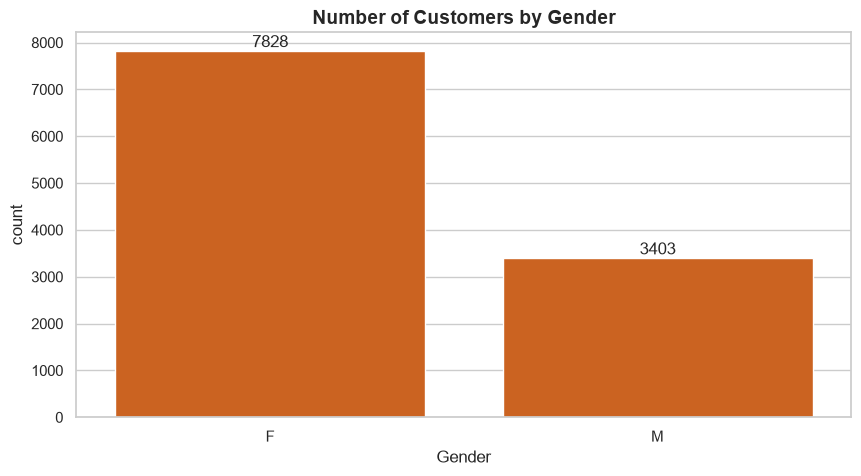

Gender
F    69.7 %
M    30.3 %
Name: proportion, dtype: str


In [10]:
# Count plot: how many customers of each gender
ax = sns.countplot(data=df, x="Gender")
plt.title("Number of Customers by Gender")

# Write the exact count on top of every bar (makes the chart easy to read)
for bar in ax.containers:
    ax.bar_label(bar)
plt.show()

# Percentage share of each gender
print((df["Gender"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

#### 5.5.2 Age Group

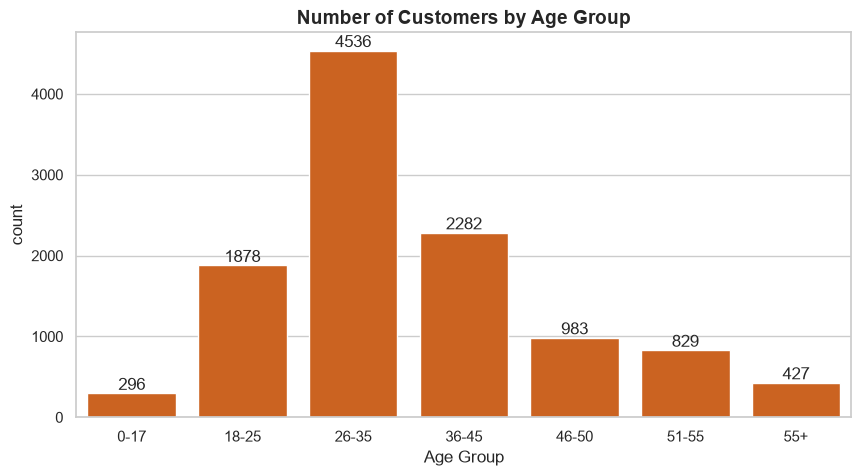

In [11]:
# Order the age groups logically (youngest to oldest) so the chart reads left to right
age_order = ["0-17", "18-25", "26-35", "36-45", "46-50", "51-55", "55+"]
age_order = [a for a in age_order if a in df["Age Group"].unique()]   # keep only groups that exist

ax = sns.countplot(data=df, x="Age Group", order=age_order)
plt.title("Number of Customers by Age Group")
for bar in ax.containers:
    ax.bar_label(bar)
plt.show()

#### 5.5.3 Marital Status

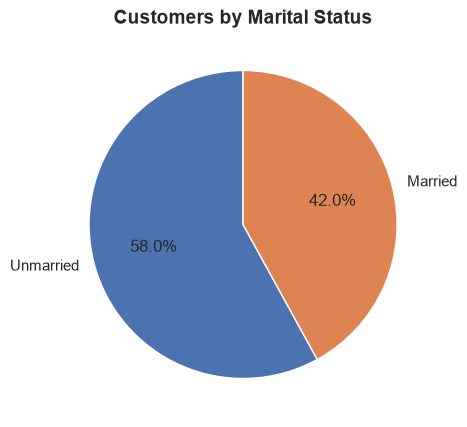

In [12]:
# Pie chart is good for showing a simple 2-category share
df["Marital_Status"].value_counts().plot.pie(
    autopct="%1.1f%%",      # show percentage on each slice
    startangle=90,          # rotate so the first slice starts at the top
    colors=["#4c72b0", "#dd8452"]
)
plt.title("Customers by Marital Status")
plt.ylabel("")              # remove the default y-label for a cleaner look
plt.show()

#### 5.5.4 Top 10 States by Number of Orders

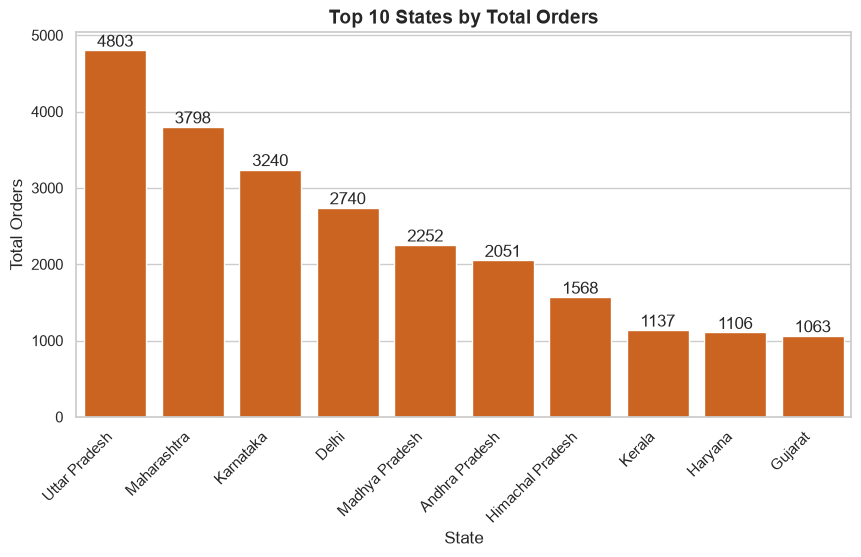

In [13]:
# Sum the orders per state and keep the 10 highest
top_states_orders = df.groupby("State")["Orders"].sum().sort_values(ascending=False).head(10)

ax = sns.barplot(x=top_states_orders.index, y=top_states_orders.values)
plt.title("Top 10 States by Total Orders")
plt.xlabel("State")
plt.ylabel("Total Orders")
plt.xticks(rotation=45, ha="right")   # tilt state names so they don't overlap
for bar in ax.containers:
    ax.bar_label(bar)
plt.show()

#### 5.5.5 Zone, Occupation and Product Category

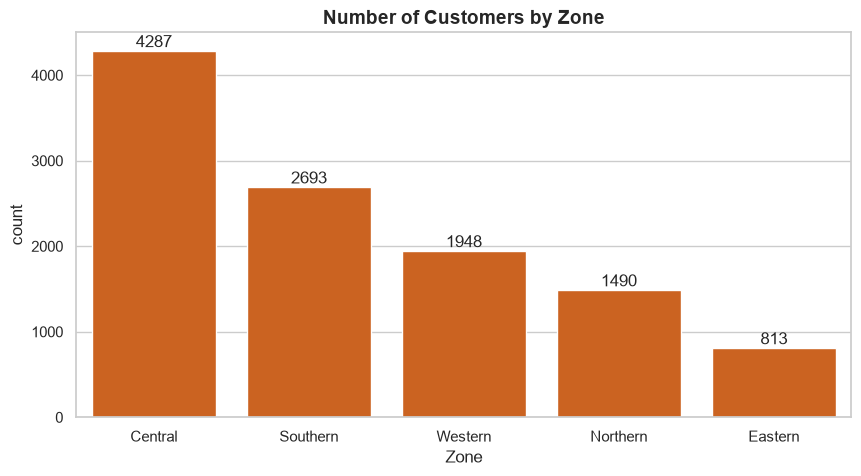

In [14]:
# Zone-wise customer count
ax = sns.countplot(data=df, x="Zone", order=df["Zone"].value_counts().index)
plt.title("Number of Customers by Zone")
for bar in ax.containers:
    ax.bar_label(bar)
plt.show()

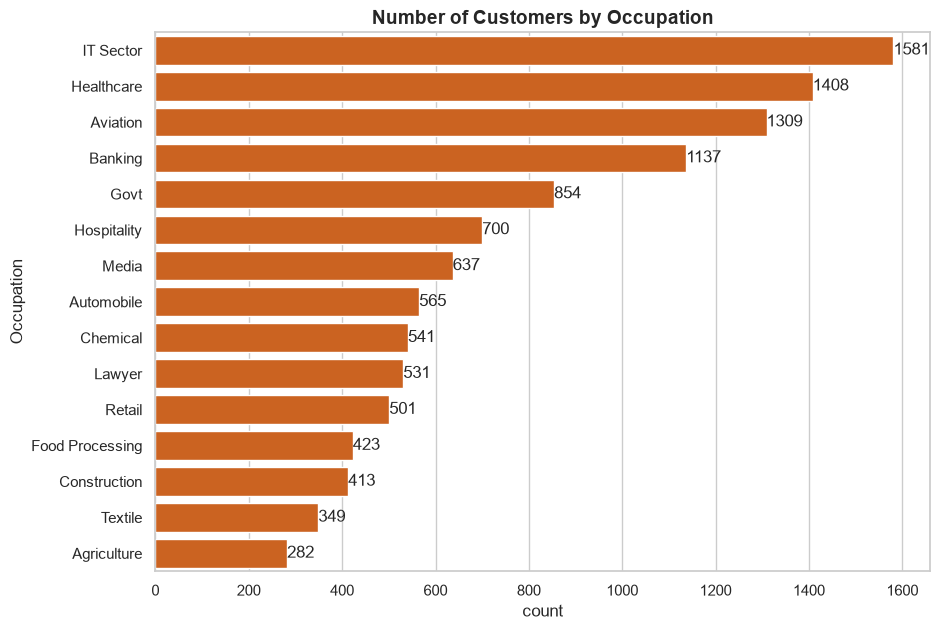

In [15]:
# Occupation-wise customer count (horizontal bars because the names are long)
plt.figure(figsize=(10, 7))
ax = sns.countplot(data=df, y="Occupation", order=df["Occupation"].value_counts().index)
plt.title("Number of Customers by Occupation")
for bar in ax.containers:
    ax.bar_label(bar)
plt.show()

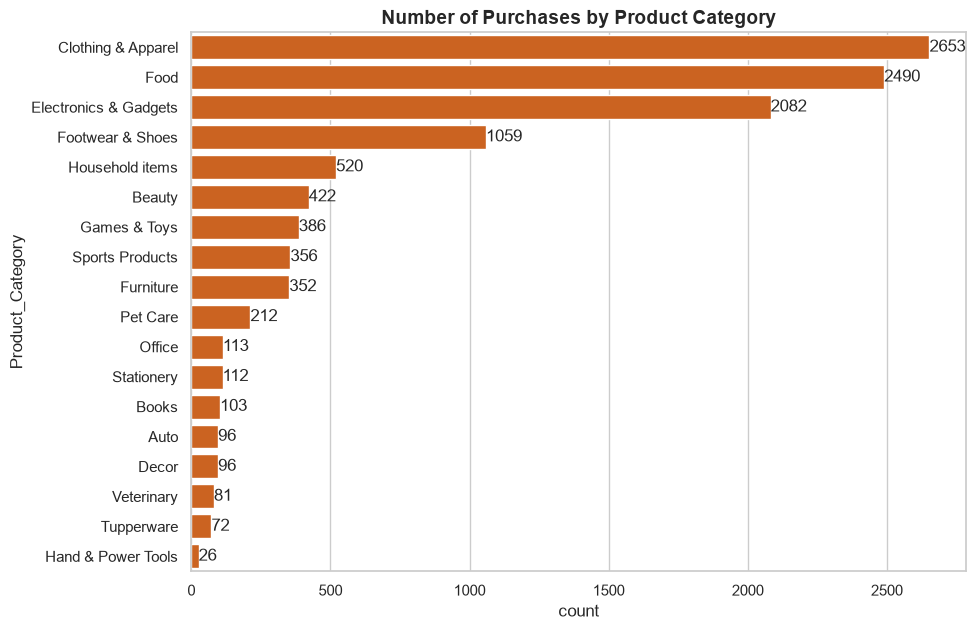

In [16]:
# Product-category-wise customer count
plt.figure(figsize=(10, 7))
ax = sns.countplot(data=df, y="Product_Category", order=df["Product_Category"].value_counts().index)
plt.title("Number of Purchases by Product Category")
for bar in ax.containers:
    ax.bar_label(bar)
plt.show()

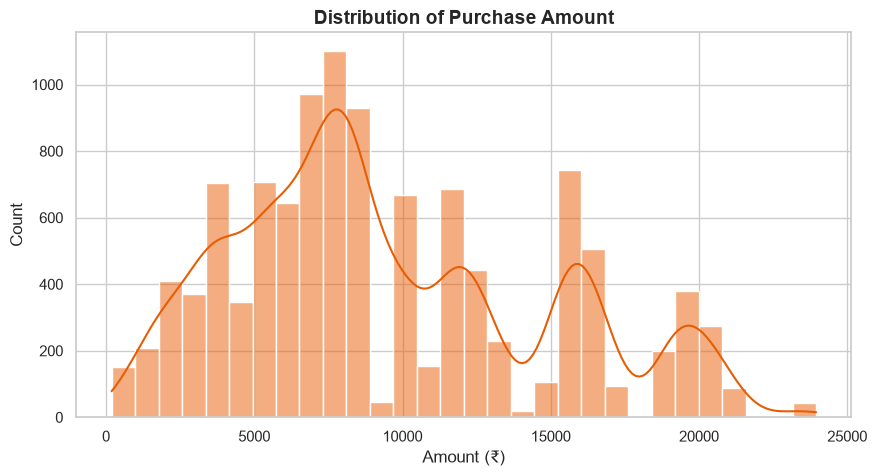

In [17]:
# Distribution of the Amount column - shows how spending is spread out
sns.histplot(df["Amount"], bins=30, kde=True)   # kde=True adds a smooth density curve
plt.title("Distribution of Purchase Amount")
plt.xlabel("Amount (₹)")
plt.show()

**Univariate Observations**
- Compare the bar heights above: the larger customer group in *Gender* and *Age Group* tells us who our core audience is.
- A few states and occupations dominate the data, while many others have only a small share.

### 5.6 Bivariate & Multivariate Analysis
*Analysing how two or more variables relate — mainly how they affect **spending (Amount)**.*

#### 5.6.1 Gender vs Total Amount Spent

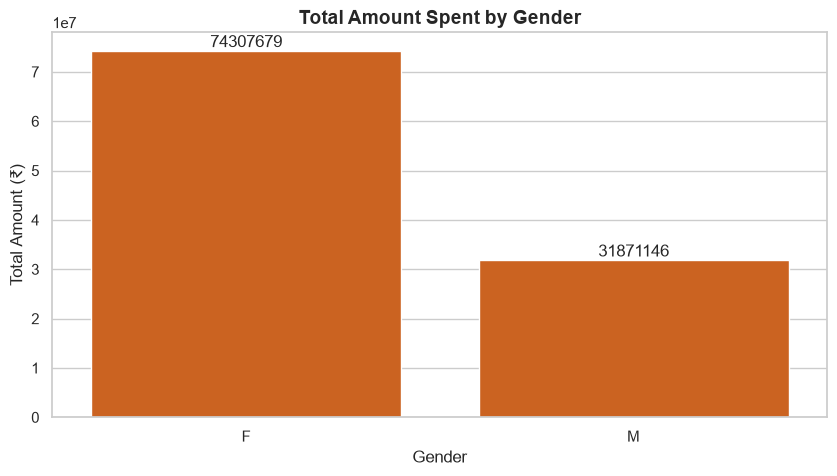

In [18]:
# Total spend per gender
gender_amt = df.groupby("Gender", as_index=False)["Amount"].sum()

ax = sns.barplot(data=gender_amt, x="Gender", y="Amount")
plt.title("Total Amount Spent by Gender")
plt.ylabel("Total Amount (₹)")
for bar in ax.containers:
    ax.bar_label(bar, fmt="%.0f")
plt.show()

#### 5.6.2 Age Group vs Total Amount (split by Gender)

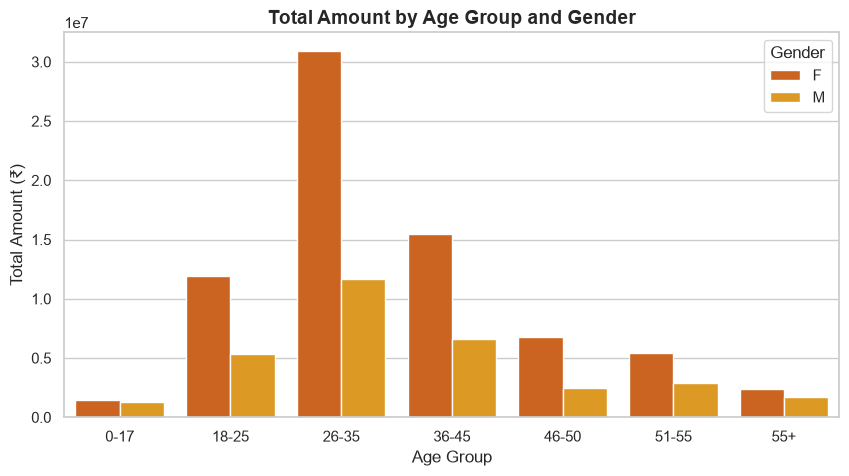

In [19]:
# hue="Gender" splits every age-group bar into male/female, so we compare both at once
age_gender_amt = df.groupby(["Age Group", "Gender"], as_index=False)["Amount"].sum()

sns.barplot(data=age_gender_amt, x="Age Group", y="Amount", hue="Gender", order=age_order)
plt.title("Total Amount by Age Group and Gender")
plt.ylabel("Total Amount (₹)")
plt.show()

#### 5.6.3 Top 10 States by Total Sales Amount

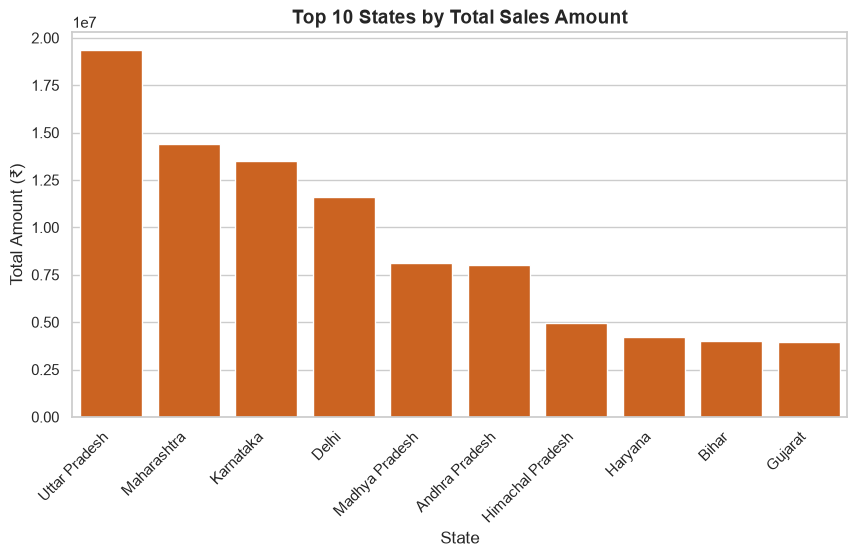

State
Uttar Pradesh       19346055
Maharashtra         14404467
Karnataka           13523540
Delhi               11603818
Madhya Pradesh       8101142
Andhra Pradesh       8037146
Himachal Pradesh     4963368
Haryana              4217871
Bihar                4014669
Gujarat              3938159
Name: Amount, dtype: int64

In [20]:
# Total revenue per state, highest first, keep top 10
top_states_amt = df.groupby("State")["Amount"].sum().sort_values(ascending=False).head(10)

ax = sns.barplot(x=top_states_amt.index, y=top_states_amt.values)
plt.title("Top 10 States by Total Sales Amount")
plt.ylabel("Total Amount (₹)")
plt.xticks(rotation=45, ha="right")
plt.show()

top_states_amt

#### 5.6.4 Marital Status & Gender vs Amount

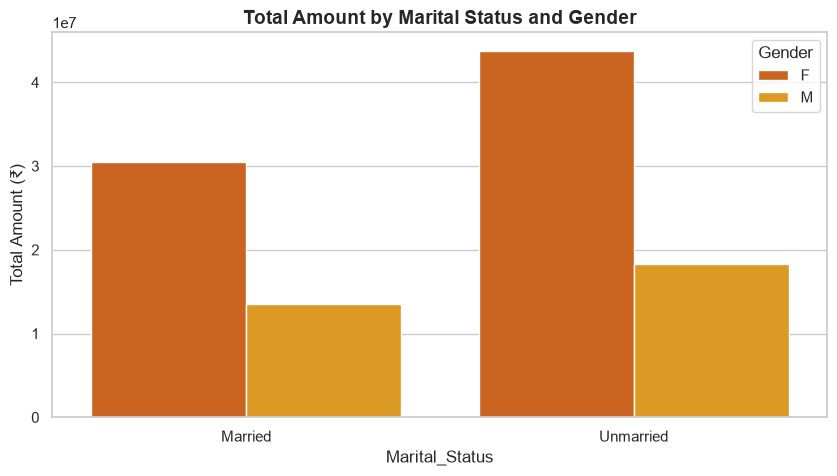

In [21]:
# Combine marital status AND gender to find the highest-spending segment
ms_gender = df.groupby(["Marital_Status", "Gender"], as_index=False)["Amount"].sum()

sns.barplot(data=ms_gender, x="Marital_Status", y="Amount", hue="Gender")
plt.title("Total Amount by Marital Status and Gender")
plt.ylabel("Total Amount (₹)")
plt.show()

#### 5.6.5 Occupation vs Total Amount

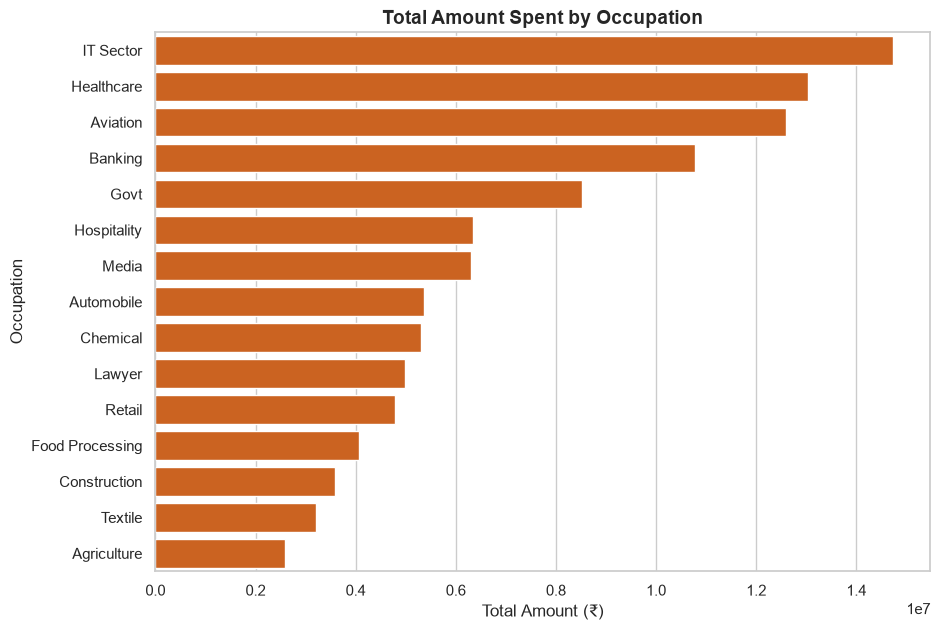

In [22]:
# Which professions spend the most? Sort by total amount, highest first
occ_amt = df.groupby("Occupation", as_index=False)["Amount"].sum().sort_values("Amount", ascending=False)

plt.figure(figsize=(10, 7))
sns.barplot(data=occ_amt, y="Occupation", x="Amount")
plt.title("Total Amount Spent by Occupation")
plt.xlabel("Total Amount (₹)")
plt.show()

#### 5.6.6 Product Category vs Total Amount

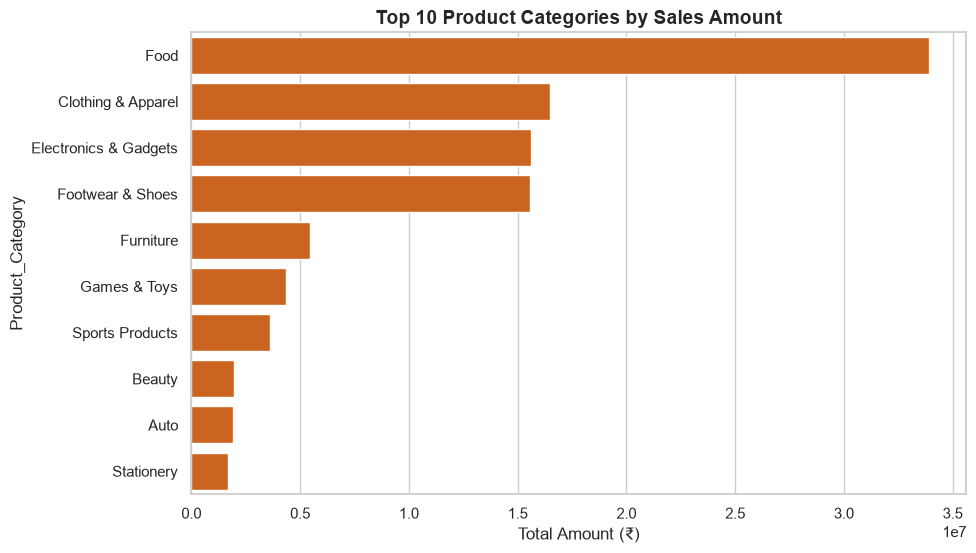

In [23]:
# Revenue per product category (top 10)
cat_amt = df.groupby("Product_Category", as_index=False)["Amount"].sum().sort_values("Amount", ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(data=cat_amt, y="Product_Category", x="Amount")
plt.title("Top 10 Product Categories by Sales Amount")
plt.xlabel("Total Amount (₹)")
plt.show()

#### 5.6.7 Zone vs Total Amount

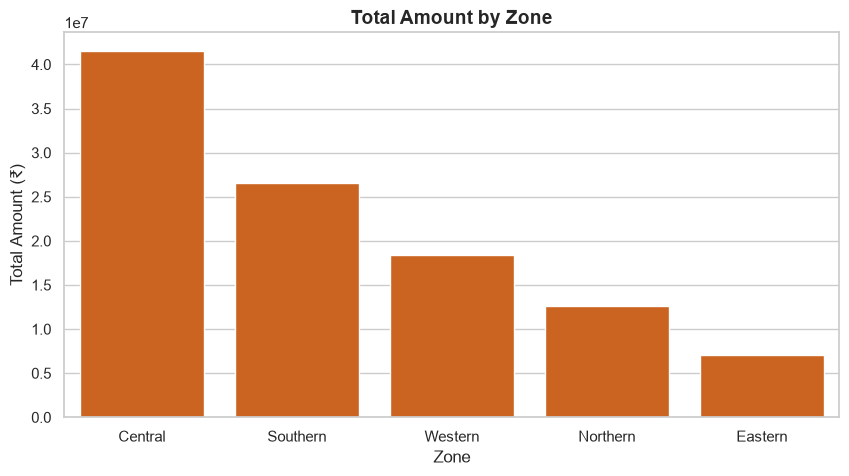

In [24]:
# Zone-wise revenue - shows which region of India contributes the most
zone_amt = df.groupby("Zone", as_index=False)["Amount"].sum().sort_values("Amount", ascending=False)

ax = sns.barplot(data=zone_amt, x="Zone", y="Amount")
plt.title("Total Amount by Zone")
plt.ylabel("Total Amount (₹)")
plt.show()

#### 5.6.8 Heatmap — Age Group × Gender Spending

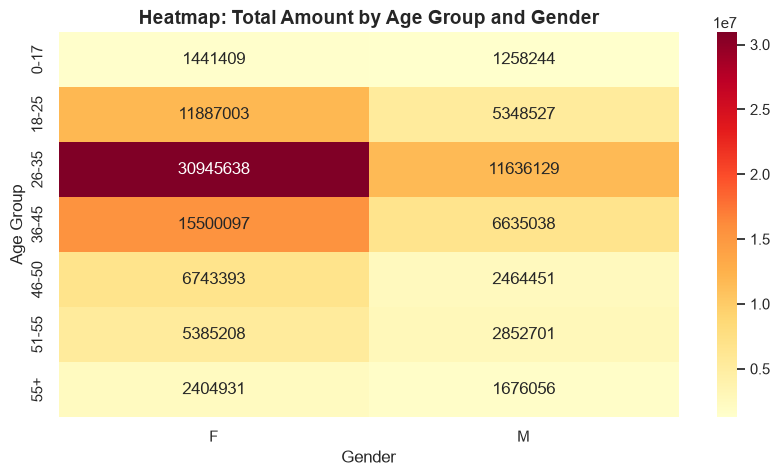

In [25]:
# pivot_table reshapes data into a grid: rows = Age Group, columns = Gender, values = total Amount
heat = df.pivot_table(index="Age Group", columns="Gender", values="Amount", aggfunc="sum")
heat = heat.reindex(age_order)   # keep age groups in logical order

sns.heatmap(heat, annot=True, fmt=".0f", cmap="YlOrRd")  # annot=True prints numbers in each cell
plt.title("Heatmap: Total Amount by Age Group and Gender")
plt.show()

#### 5.6.9 Correlation between numeric columns

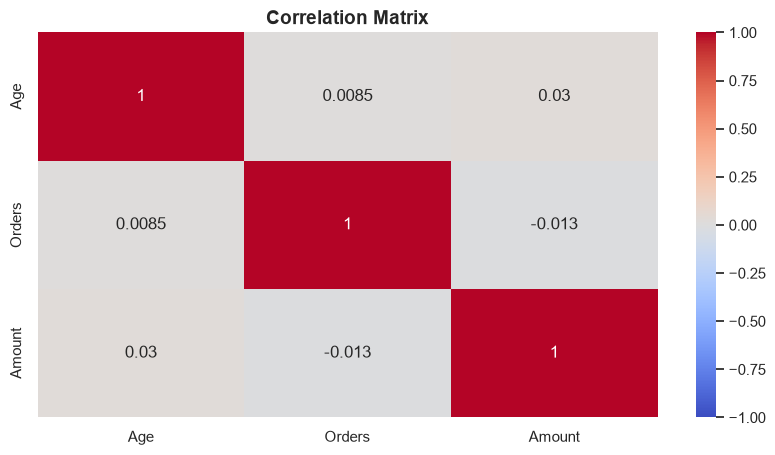

In [26]:
# Correlation shows how strongly numeric columns move together (-1 to +1)
corr = df[["Age", "Orders", "Amount"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

### 5.7 Advanced Visualisations — Heatmaps, Matrices & More
*This section adds richer charts — **KPI cards, donut charts, heatmaps, correlation matrix, box/violin plots,
Pareto chart, bubble chart, stacked bars and a pairplot** — to make the insights easy to see at a glance.*

#### 5.7.1 KPI Cards — Business Snapshot

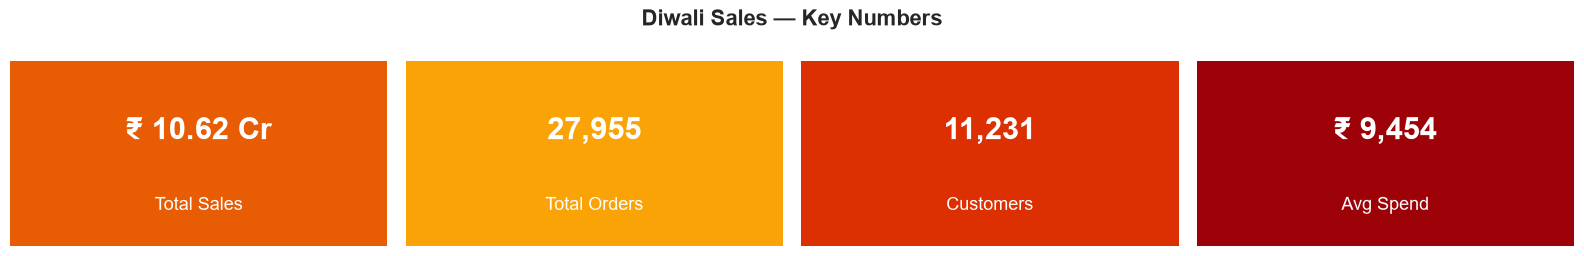

In [27]:
# KPI = Key Performance Indicator. We compute 4 headline numbers and show them as big "cards".
total_sales   = df["Amount"].sum()        # total money spent by all customers
total_orders  = df["Orders"].sum()        # total number of orders placed
total_cust    = len(df)                   # number of transaction records (customers)
avg_order_val = df["Amount"].mean()       # average spend per record

# Each tuple = (card title, value to display, card colour)
kpis = [("Total Sales", f"₹ {total_sales/1e7:.2f} Cr", DIWALI[0]),
        ("Total Orders", f"{total_orders:,}", DIWALI[1]),
        ("Customers", f"{total_cust:,}", DIWALI[2]),
        ("Avg Spend", f"₹ {avg_order_val:,.0f}", DIWALI[3])]

fig, axes = plt.subplots(1, 4, figsize=(16, 2.6))        # 4 small boxes side by side
for ax, (title, value, colour) in zip(axes, kpis):
    ax.set_facecolor(colour)                              # fill the card with its colour
    ax.text(0.5, 0.62, value, ha="center", va="center", fontsize=22, color="white", fontweight="bold")
    ax.text(0.5, 0.22, title, ha="center", va="center", fontsize=13, color="white")
    ax.set_xticks([]); ax.set_yticks([])                  # remove axis numbers (we only want a card)
    ax.grid(False)
    for spine in ax.spines.values():                      # remove the box border
        spine.set_visible(False)
fig.suptitle("Diwali Sales — Key Numbers", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

#### 5.7.2 Donut Charts — Share of Sales

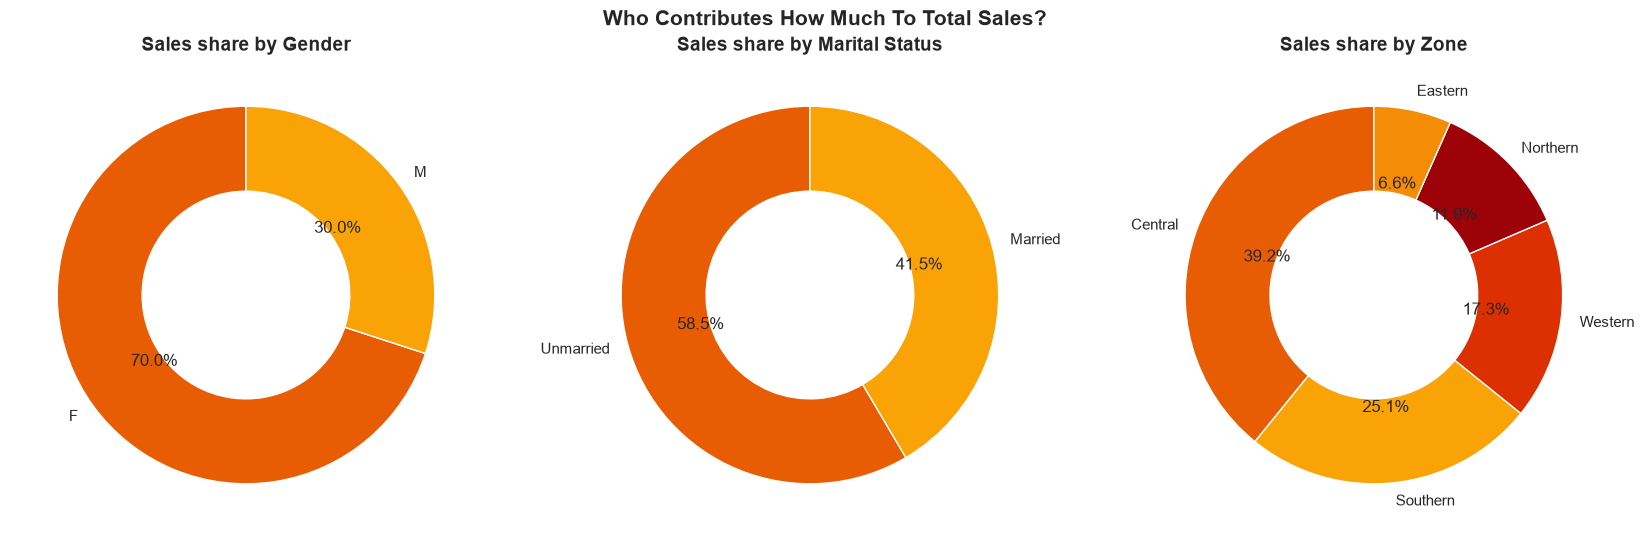

In [28]:
# A donut chart is a pie chart with a hole - it shows each group's share of the total.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))

# Three different columns whose sales share we want to compare
for ax, col in zip(axes, ["Gender", "Marital_Status", "Zone"]):
    share = df.groupby(col)["Amount"].sum().sort_values(ascending=False)   # total sales per group
    ax.pie(share.values, labels=share.index, autopct="%1.1f%%", startangle=90,
           colors=DIWALI[:len(share)],
           wedgeprops=dict(width=0.45, edgecolor="white"))                 # width<1 makes the hole
    ax.set_title(f"Sales share by {col.replace('_', ' ')}")

plt.suptitle("Who Contributes How Much To Total Sales?", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

#### 5.7.3 Heatmap — State × Product Category (Sales in ₹ Lakh)

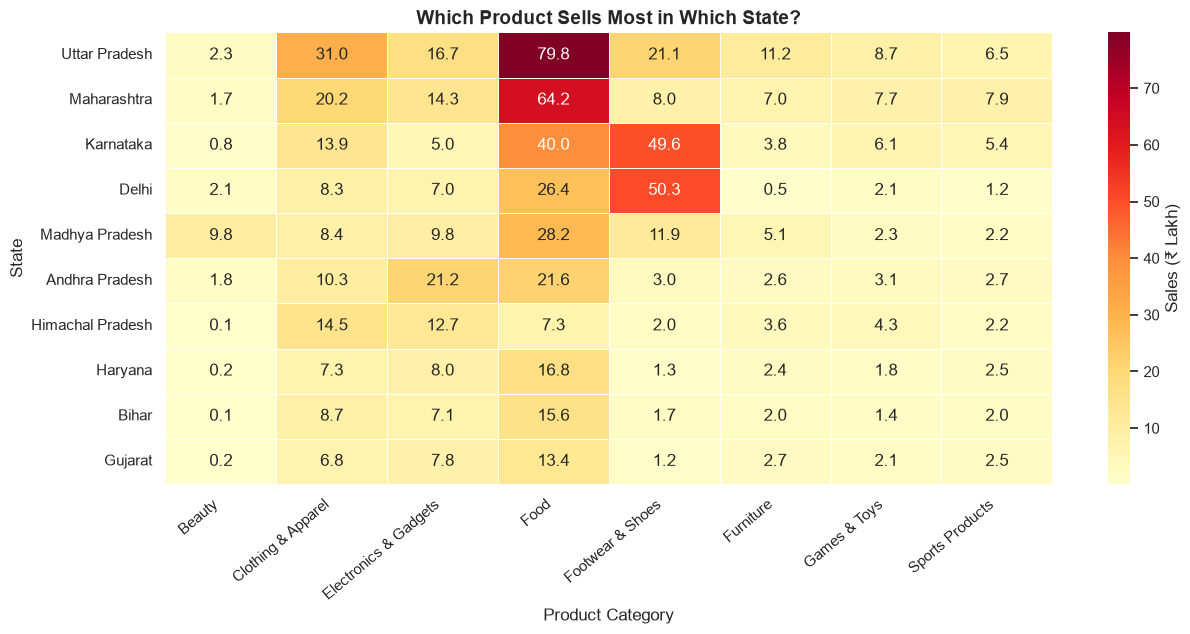

In [29]:
# Keep only the top 10 states and top 8 categories so the heatmap stays readable
top_states = df.groupby("State")["Amount"].sum().nlargest(10).index
top_cats   = df.groupby("Product_Category")["Amount"].sum().nlargest(8).index
subset = df[df["State"].isin(top_states) & df["Product_Category"].isin(top_cats)]

# pivot_table builds a grid: rows = State, columns = Product Category, cell = total sales.
# Dividing by 1,00,000 converts rupees into lakhs so numbers are short and readable.
grid = subset.pivot_table(index="State", columns="Product_Category",
                          values="Amount", aggfunc="sum", fill_value=0) / 1e5
grid = grid.loc[top_states]    # keep the states in order of highest sales first

plt.figure(figsize=(13, 6.5))
sns.heatmap(grid, annot=True, fmt=".1f", cmap=HEAT, linewidths=0.5,
            cbar_kws={"label": "Sales (₹ Lakh)"})     # annot=True prints the number inside each box
plt.title("Which Product Sells Most in Which State?")
plt.xlabel("Product Category")
plt.ylabel("State")
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.show()

#### 5.7.4 Heatmap — Occupation × Age Group (Sales in ₹ Lakh)

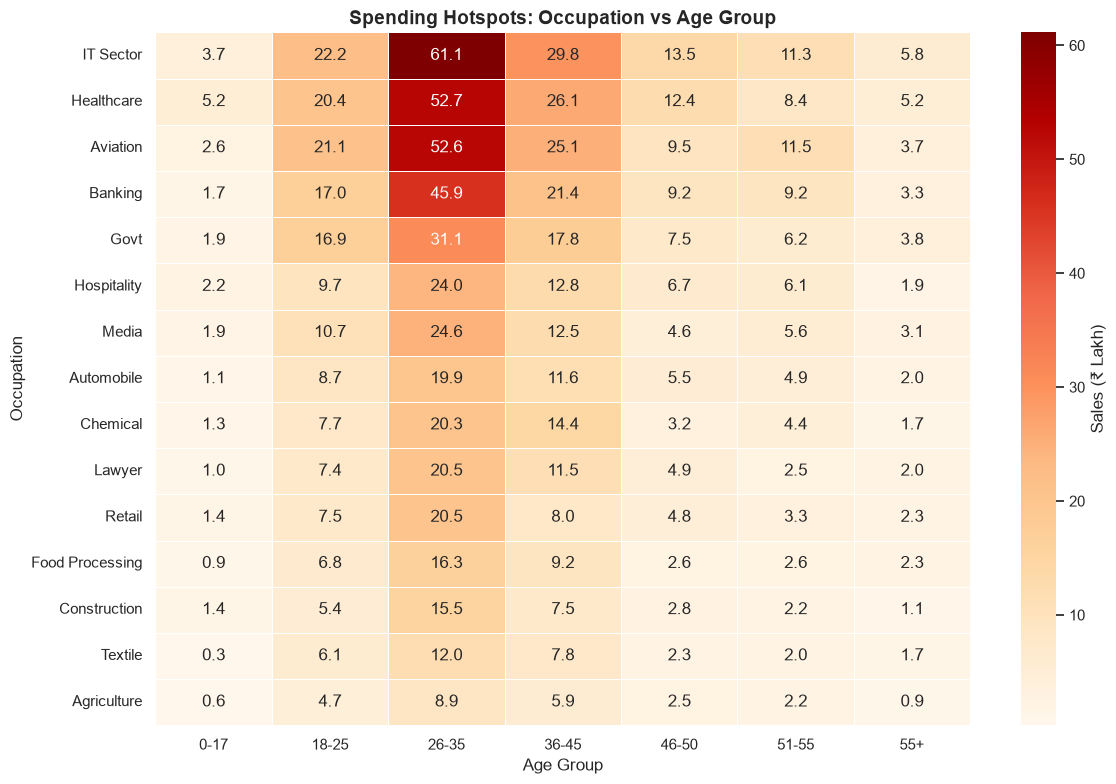

In [30]:
# Same idea: dark cells = customer segments that spend the most
occ_age = df.pivot_table(index="Occupation", columns="Age Group",
                         values="Amount", aggfunc="sum", fill_value=0) / 1e5
occ_age = occ_age[age_order]                                          # keep age groups in logical order
occ_age = occ_age.loc[occ_age.sum(axis=1).sort_values(ascending=False).index]   # richest occupations on top

plt.figure(figsize=(12, 8))
sns.heatmap(occ_age, annot=True, fmt=".1f", cmap="OrRd", linewidths=0.5,
            cbar_kws={"label": "Sales (₹ Lakh)"})
plt.title("Spending Hotspots: Occupation vs Age Group")
plt.tight_layout()
plt.show()

#### 5.7.5 Cross-Tab Matrices — Customer Counts and Average Spend

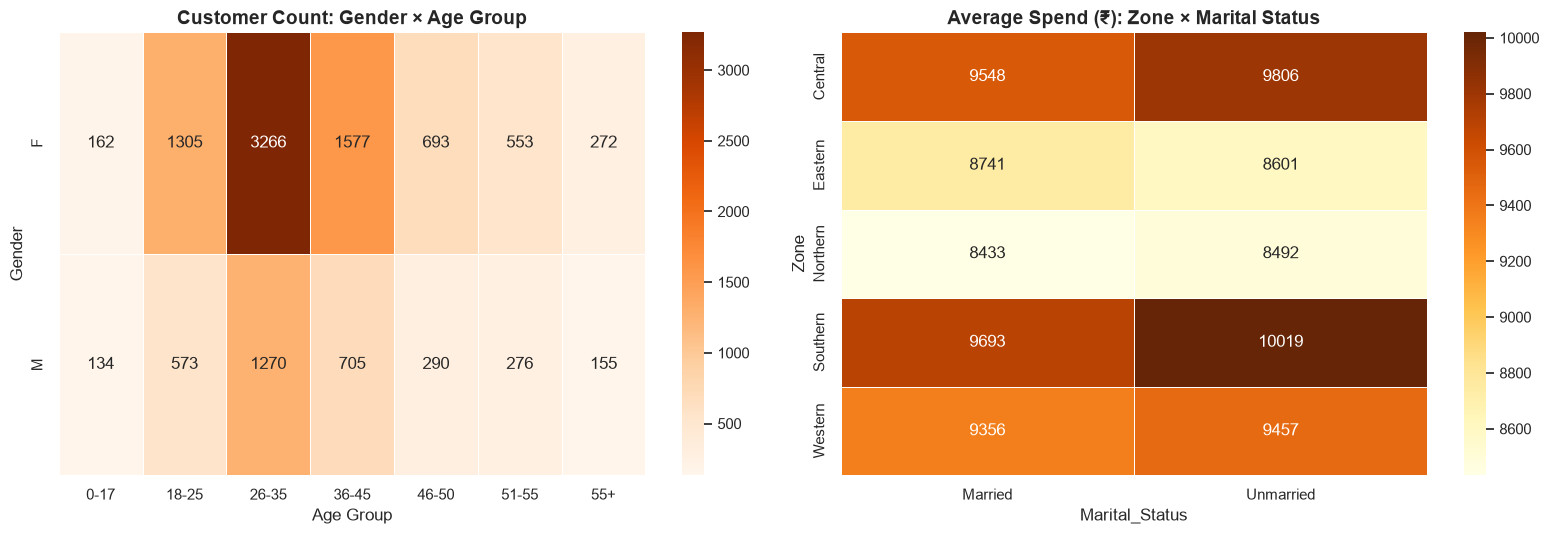

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# LEFT matrix: how many customers fall in each (Gender, Age Group) combination
count_matrix = pd.crosstab(df["Gender"], df["Age Group"])[age_order]     # crosstab counts occurrences
sns.heatmap(count_matrix, annot=True, fmt="d", cmap="Oranges", linewidths=0.5, ax=axes[0])
axes[0].set_title("Customer Count: Gender × Age Group")

# RIGHT matrix: average spend per customer for each (Zone, Marital Status) combination
avg_matrix = df.pivot_table(index="Zone", columns="Marital_Status", values="Amount", aggfunc="mean")
sns.heatmap(avg_matrix, annot=True, fmt=".0f", cmap="YlOrBr", linewidths=0.5, ax=axes[1])
axes[1].set_title("Average Spend (₹): Zone × Marital Status")

plt.tight_layout()
plt.show()

#### 5.7.6 Correlation Matrix (Lower-Triangle Heatmap)

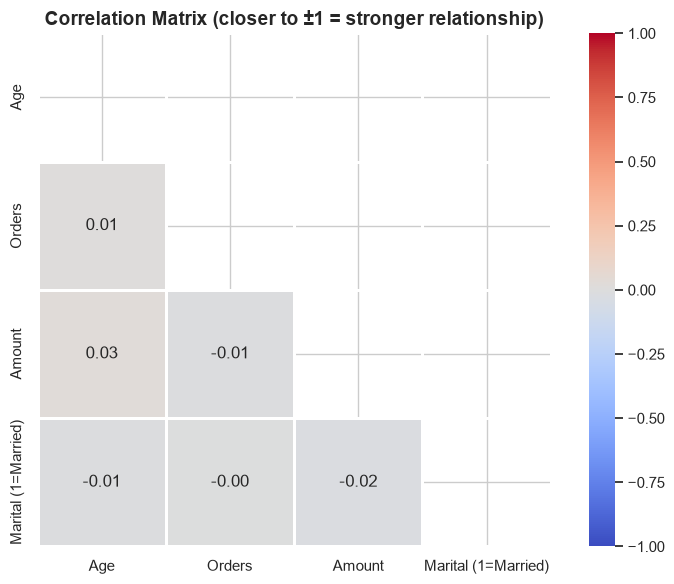

In [32]:
# Make a numeric copy of the data. Marital status is text, so we turn it into 0/1 to correlate it.
num_df = df[["Age", "Orders", "Amount"]].copy()
num_df["Marital (1=Married)"] = (df["Marital_Status"] == "Married").astype(int)

corr = num_df.corr()                                  # correlation between every pair of columns

# 'mask' hides the upper triangle because it is just a mirror image of the lower one
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, linewidths=1, square=True)
plt.title("Correlation Matrix (closer to ±1 = stronger relationship)")
plt.tight_layout()
plt.show()

**Reading the correlation matrix:** a value near **+1** means both columns rise together, near **-1** means one rises
while the other falls, and near **0** means no linear relationship. In this data, *Orders* and *Amount* are the
pair worth watching — customers who place more orders tend to spend more.

#### 5.7.7 Box Plot & Violin Plot — Spending Spread and Outliers

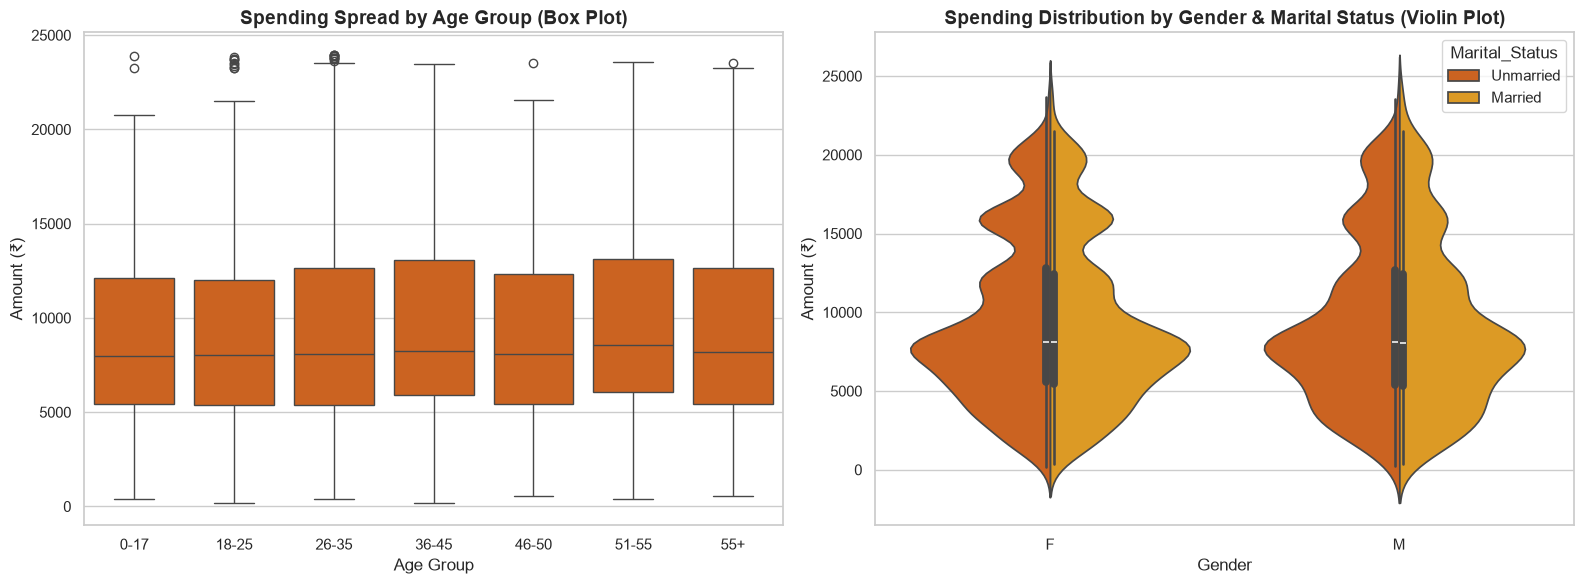

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# BOX PLOT: the box = middle 50% of customers, the line inside = median, dots = unusually high/low spenders
sns.boxplot(data=df, x="Age Group", y="Amount", order=age_order, ax=axes[0])
axes[0].set_title("Spending Spread by Age Group (Box Plot)")
axes[0].set_ylabel("Amount (₹)")

# VIOLIN PLOT: the width of the shape shows where most customers' spending is concentrated
sns.violinplot(data=df, x="Gender", y="Amount", hue="Marital_Status", split=True, ax=axes[1])
axes[1].set_title("Spending Distribution by Gender & Marital Status (Violin Plot)")
axes[1].set_ylabel("Amount (₹)")

plt.tight_layout()
plt.show()

#### 5.7.8 Scatter Plots — Orders vs Amount, Age vs Amount

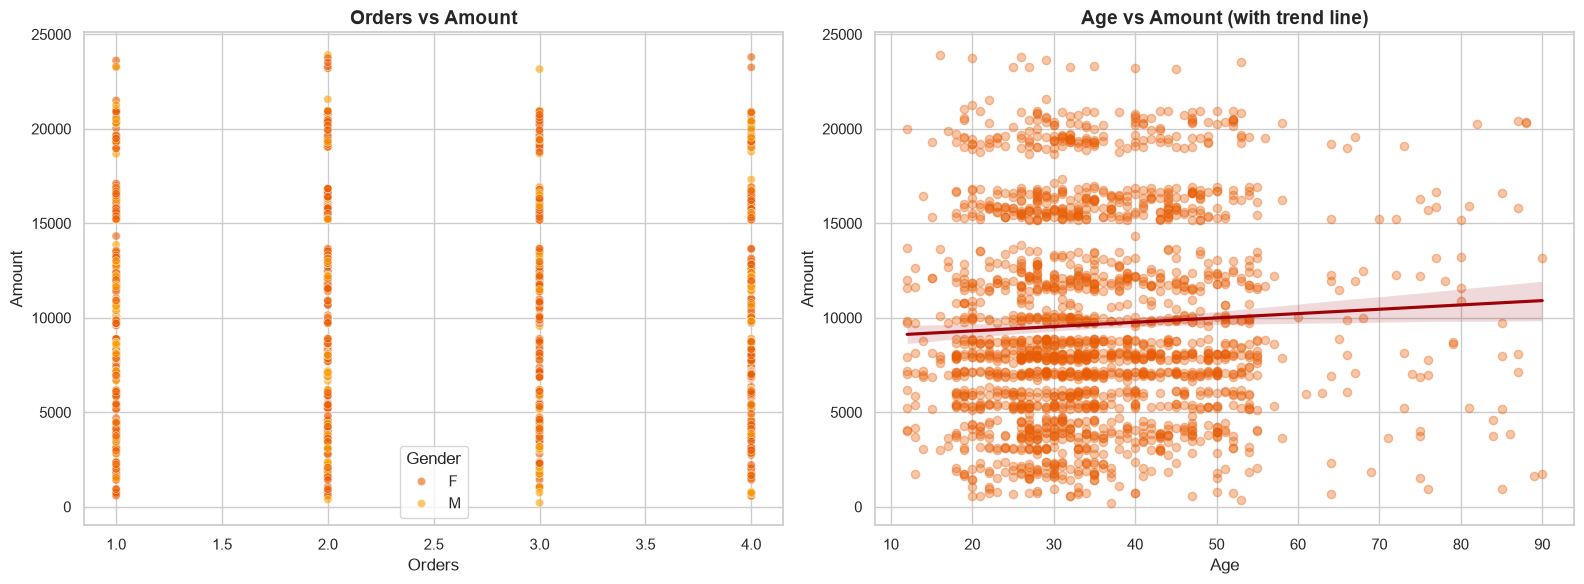

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Take a random sample of 2000 rows so the scatter plot stays fast and not too crowded
sample = df.sample(n=min(2000, len(df)), random_state=42)   # random_state makes the sample repeatable

# LEFT: each dot is a customer; colour shows gender
sns.scatterplot(data=sample, x="Orders", y="Amount", hue="Gender", alpha=0.6, ax=axes[0])
axes[0].set_title("Orders vs Amount")

# RIGHT: regplot also draws a trend line (the straight line shows the overall direction)
sns.regplot(data=sample, x="Age", y="Amount", scatter_kws={"alpha": 0.35, "color": DIWALI[0]},
            line_kws={"color": DIWALI[3]}, ax=axes[1])
axes[1].set_title("Age vs Amount (with trend line)")

plt.tight_layout()
plt.show()

#### 5.7.9 Pareto Chart — Do a Few States Drive Most Sales? (80/20 Rule)

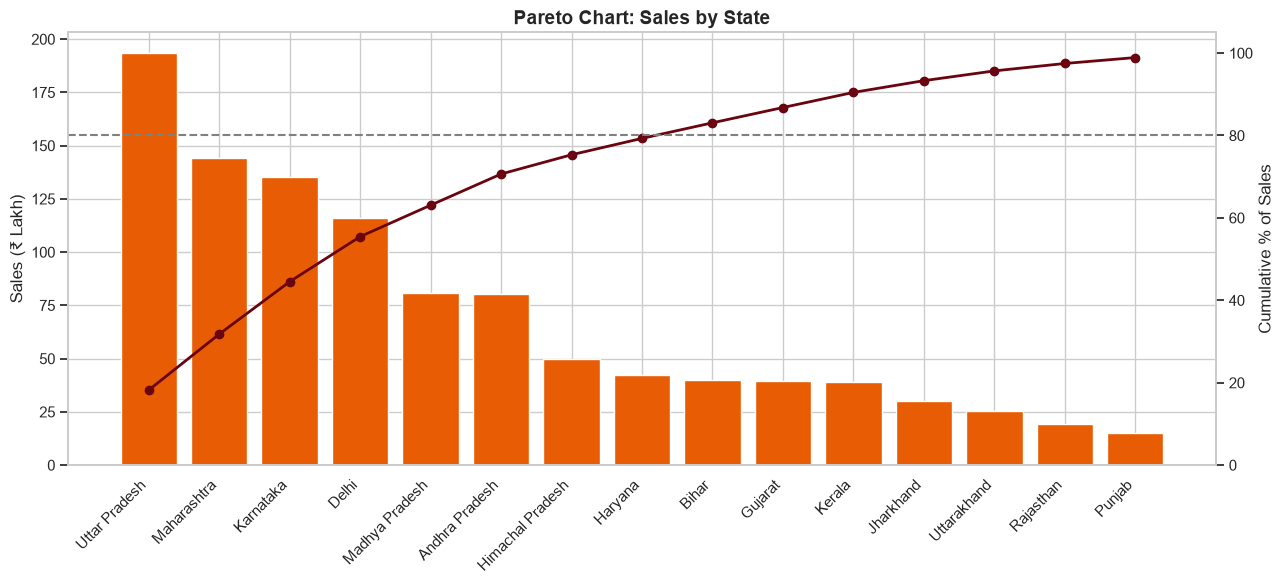

Top 9 states generate about 80% of total sales.


In [35]:
# Total sales per state, highest first
state_sales = df.groupby("State")["Amount"].sum().sort_values(ascending=False)
cum_pct = state_sales.cumsum() / state_sales.sum() * 100       # running total as a percentage

n = min(15, len(state_sales))                                  # show at most the top 15 states
fig, ax1 = plt.subplots(figsize=(13, 6))

# Bars = sales of each state (in ₹ lakh)
ax1.bar(state_sales.index[:n], state_sales.values[:n] / 1e5, color=DIWALI[0])
ax1.set_ylabel("Sales (₹ Lakh)")
ax1.set_xticklabels(state_sales.index[:n], rotation=45, ha="right")

# Line = cumulative percentage (uses a second y-axis on the right)
ax2 = ax1.twinx()
ax2.plot(state_sales.index[:n], cum_pct.values[:n], color=DIWALI[5], marker="o", linewidth=2)
ax2.axhline(80, color="grey", linestyle="--")                  # the 80% reference line
ax2.set_ylim(0, 105)
ax2.set_ylabel("Cumulative % of Sales")
ax2.grid(False)

plt.title("Pareto Chart: Sales by State")
plt.tight_layout()
plt.show()

# Print how many states are needed to reach 80% of sales
print(f"Top {(cum_pct < 80).sum() + 1} states generate about 80% of total sales.")

#### 5.7.10 Bubble Chart — State Performance (Orders vs Sales vs Customers)

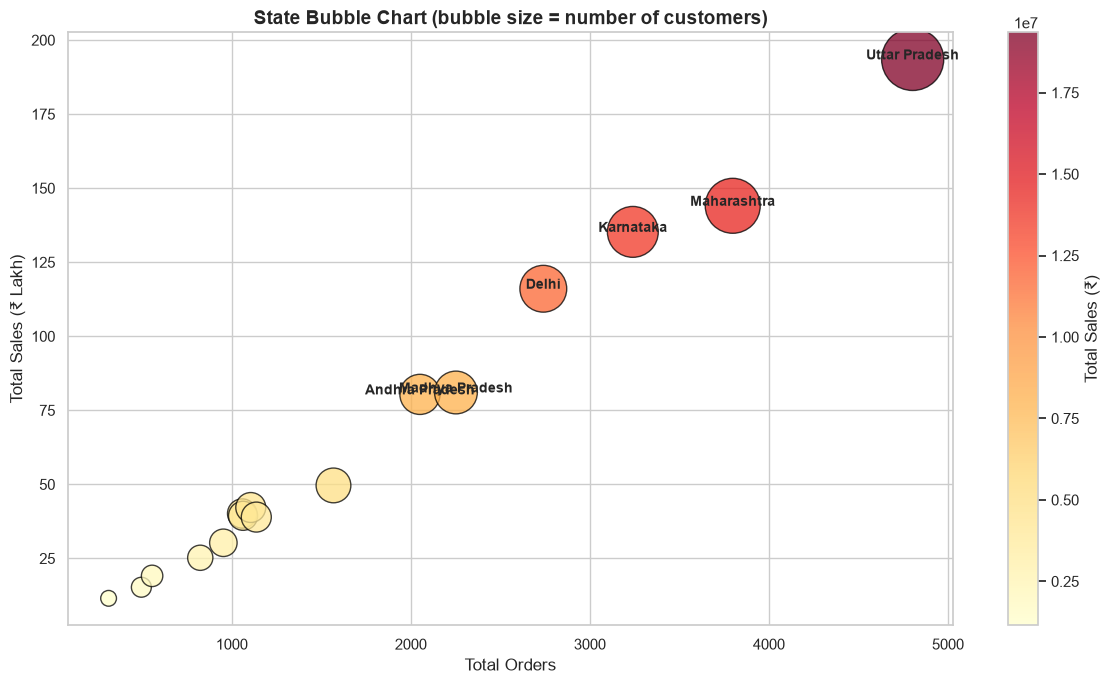

In [36]:
# One row per state with 3 measures: total orders, total sales and number of customers
state_stats = df.groupby("State").agg(Orders=("Orders", "sum"),
                                      Sales=("Amount", "sum"),
                                      Customers=("Amount", "size"))

plt.figure(figsize=(12, 7))
plt.scatter(state_stats["Orders"], state_stats["Sales"] / 1e5,
            s=state_stats["Customers"] / state_stats["Customers"].max() * 2000,   # bubble size = customers
            c=state_stats["Sales"], cmap="YlOrRd", alpha=0.75, edgecolors="black")

# Label the 6 biggest states so the chart is easy to read
for state, row in state_stats.nlargest(6, "Sales").iterrows():
    plt.annotate(state, (row["Orders"], row["Sales"] / 1e5), ha="center", fontsize=10, fontweight="bold")

plt.xlabel("Total Orders")
plt.ylabel("Total Sales (₹ Lakh)")
plt.title("State Bubble Chart (bubble size = number of customers)")
plt.colorbar(label="Total Sales (₹)")
plt.tight_layout()
plt.show()

#### 5.7.11 100% Stacked Bar — Gender Mix in Each Product Category

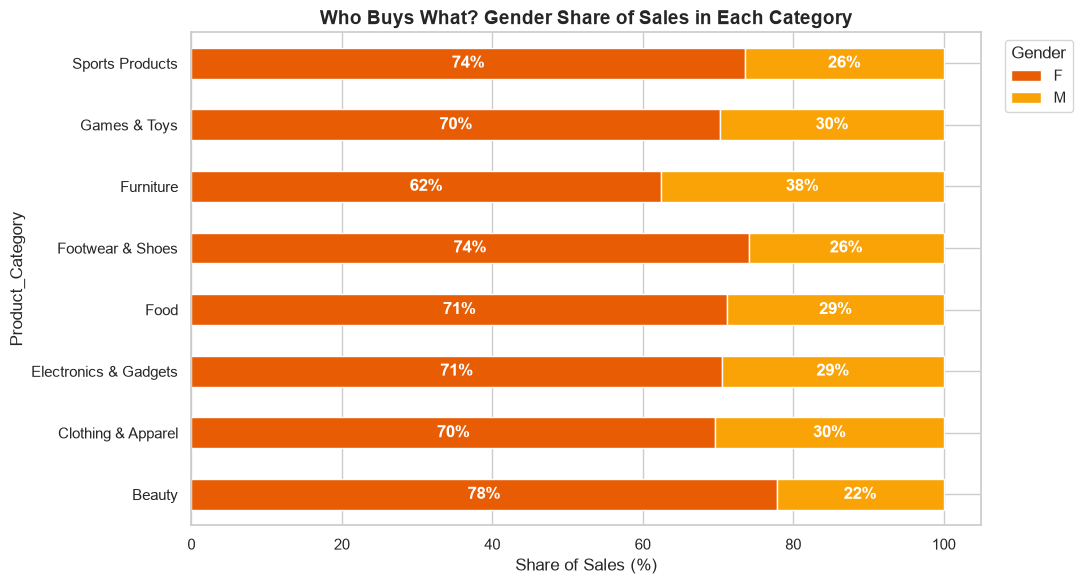

In [37]:
# Sales of each product category split by gender (top 8 categories only)
cat_gender = df[df["Product_Category"].isin(top_cats)].pivot_table(
    index="Product_Category", columns="Gender", values="Amount", aggfunc="sum")

# Divide each row by its total so every bar adds up to exactly 100%
cat_gender_pct = cat_gender.div(cat_gender.sum(axis=1), axis=0) * 100

ax = cat_gender_pct.plot(kind="barh", stacked=True, figsize=(11, 6), color=DIWALI[:2])
for bar in ax.containers:
    ax.bar_label(bar, fmt="%.0f%%", label_type="center", color="white", fontweight="bold")
plt.title("Who Buys What? Gender Share of Sales in Each Category")
plt.xlabel("Share of Sales (%)")
plt.legend(title="Gender", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

#### 5.7.12 Lollipop Chart — Average Spend per Customer by Occupation

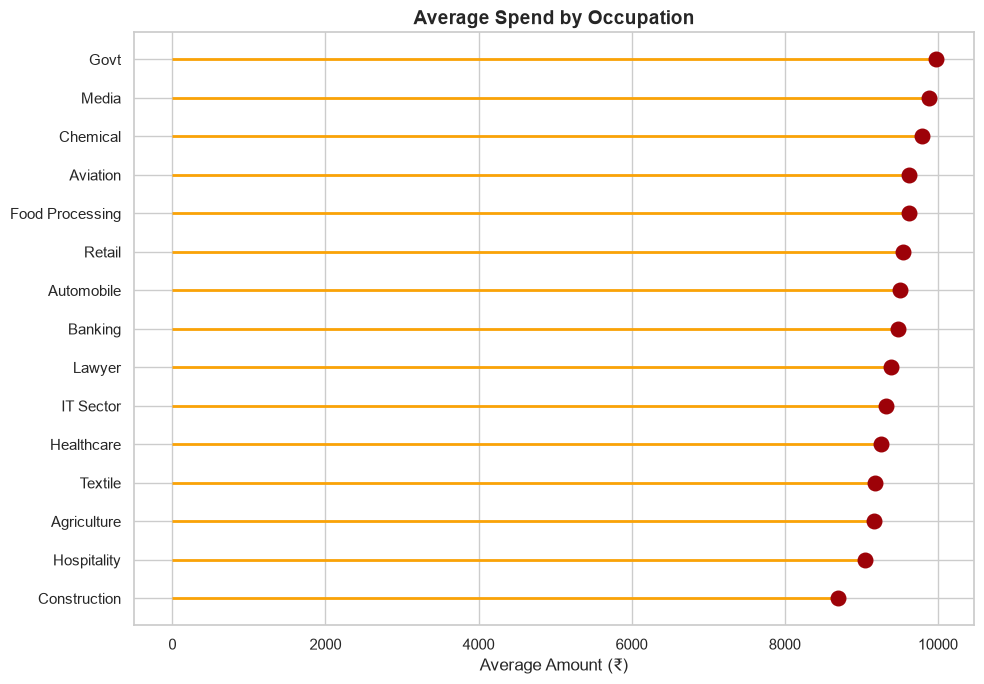

In [38]:
# Average spend by occupation, sorted so the chart reads from lowest to highest
avg_occ = df.groupby("Occupation")["Amount"].mean().sort_values()

plt.figure(figsize=(10, 7))
plt.hlines(y=avg_occ.index, xmin=0, xmax=avg_occ.values, color=DIWALI[1], linewidth=2)   # the "stick"
plt.scatter(avg_occ.values, avg_occ.index, color=DIWALI[3], s=110, zorder=3)              # the "lollipop head"
plt.title("Average Spend by Occupation")
plt.xlabel("Average Amount (₹)")
plt.tight_layout()
plt.show()

#### 5.7.13 Pair Plot — All Numeric Relationships at Once

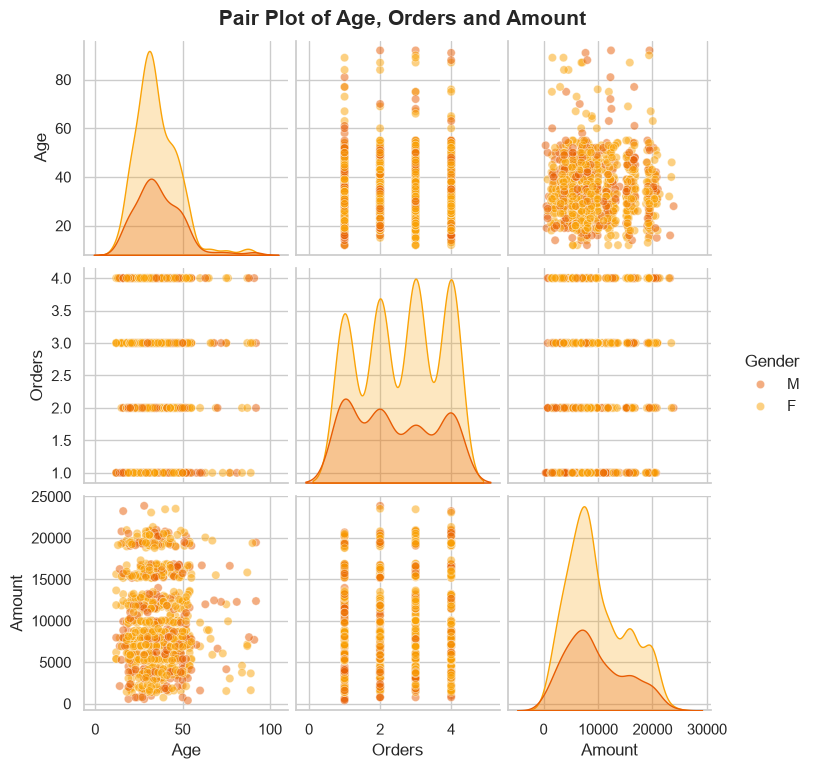

In [39]:
# A pairplot draws every numeric column against every other. We use a 1000-row sample to keep it fast.
pair_sample = df[["Age", "Orders", "Amount", "Gender"]].sample(n=min(1000, len(df)), random_state=1)

g = sns.pairplot(pair_sample, hue="Gender", palette=DIWALI[:2], diag_kind="kde",
                 plot_kws={"alpha": 0.5})      # kde on the diagonal shows each column's distribution
g.fig.suptitle("Pair Plot of Age, Orders and Amount", y=1.02, fontsize=15, fontweight="bold")
plt.show()

**Observations from the advanced visualisations**
- **Heatmaps** make it easy to spot *hotspots* — the darkest cells are the best state-category and occupation-age combinations.
- The **Pareto chart** shows that a small number of states generate most of the revenue (the 80/20 rule).
- **Box/violin plots** show that spending is spread widely and a few high spenders (outliers) exist.
- The **100% stacked bar** shows which categories are dominated by women or men customers, which helps in targeted advertising.

## 6. Use Case

**Scenario:** A retail / e-commerce company wants to plan its **next Diwali sale campaign**.

**How this analysis helps:**

| Business Need | How EDA Helps |
|---|---|
| **Targeted marketing** | Identifies the gender, age group and marital-status segment that spends the most, so ads can be aimed at them. |
| **Inventory planning** | Shows the best-selling product categories so more stock is kept for them before the festival. |
| **Regional strategy** | Reveals the top states/zones, so delivery centres and offers are focused where demand is highest. |
| **Profession-based offers** | Highlights high-spending occupations for corporate or professional tie-up discounts. |
| **Budget allocation** | Marketing budget can be distributed according to the revenue share of each segment. |

The same approach can be reused for other festive seasons (Christmas, Eid, Black Friday, etc.).

## 7. Final Output — Key Findings & Recommendations
*The findings below are calculated directly from the data, so they always match the charts above.*

In [40]:
# Helper: returns the label with the highest total Amount for a given column
def top_by_amount(col):
    s = df.groupby(col)["Amount"].sum().sort_values(ascending=False)
    return s.index[0], s.iloc[0], s.iloc[0] / s.sum() * 100   # (name, amount, % share of total)

total_sales = df["Amount"].sum()
print("=" * 60)
print("            DIWALI SALES - KEY FINDINGS")
print("=" * 60)
print(f"Total customers/transactions analysed : {len(df):,}")
print(f"Total sales amount                     : ₹ {total_sales:,.0f}")
print(f"Average order value (per transaction)  : ₹ {df['Amount'].mean():,.0f}")
print("-" * 60)

# Loop through the important columns and print the top contributor for each
for col, label in [("Gender", "Top gender"), ("Age Group", "Top age group"),
                   ("Marital_Status", "Top marital status"), ("State", "Top state"),
                   ("Zone", "Top zone"), ("Occupation", "Top occupation"),
                   ("Product_Category", "Top product category")]:
    name, amt, share = top_by_amount(col)
    print(f"{label:<22}: {name}  (₹ {amt:,.0f} | {share:.1f}% of total sales)")
print("=" * 60)

            DIWALI SALES - KEY FINDINGS
Total customers/transactions analysed : 11,231
Total sales amount                     : ₹ 106,178,825
Average order value (per transaction)  : ₹ 9,454
------------------------------------------------------------
Top gender            : F  (₹ 74,307,679 | 70.0% of total sales)
Top age group         : 26-35  (₹ 42,581,767 | 40.1% of total sales)
Top marital status    : Unmarried  (₹ 62,098,734 | 58.5% of total sales)
Top state             : Uttar Pradesh  (₹ 19,346,055 | 18.2% of total sales)
Top zone              : Central  (₹ 41,571,959 | 39.2% of total sales)
Top occupation        : IT Sector  (₹ 14,741,862 | 13.9% of total sales)
Top product category  : Food  (₹ 33,933,883 | 32.0% of total sales)


In [41]:
# Final summary table: top 5 states with their orders, sales and average spend
summary = (df.groupby("State")
             .agg(Total_Orders=("Orders", "sum"),
                  Total_Sales=("Amount", "sum"),
                  Avg_Spend=("Amount", "mean"))
             .sort_values("Total_Sales", ascending=False)
             .head(5)
             .round(0))
summary

,Total_Orders,Total_Sales,Avg_Spend
State,,,
Uttar Pradesh,4803,19346055,9962.0
Maharashtra,3798,14404467,9464.0
Karnataka,3240,13523540,10371.0
Delhi,2740,11603818,10511.0
Madhya Pradesh,2252,8101142,8796.0


### 📊 Executive Dashboard
*One page that summarises the whole analysis — ideal to show during your viva / presentation.*

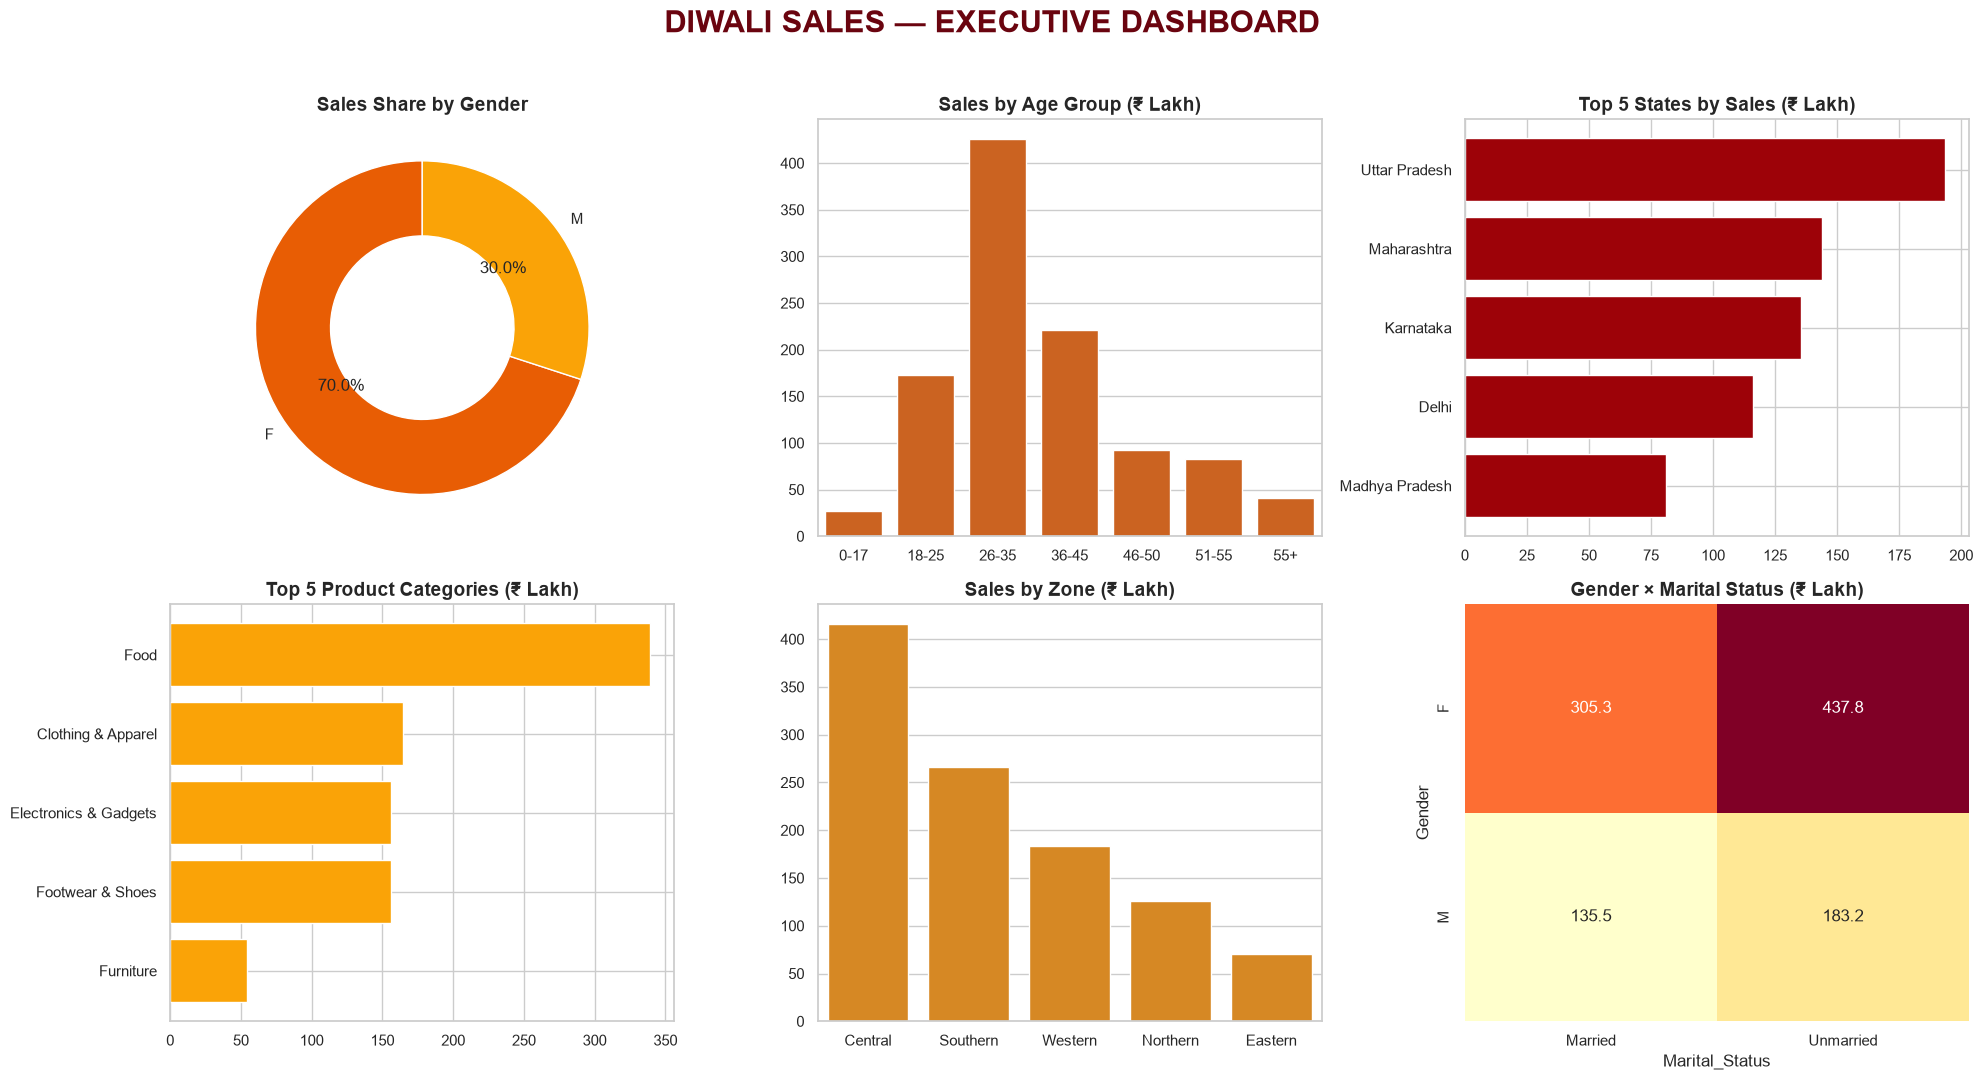

In [42]:
# Build one big figure with a 2 x 3 grid of small charts = a "dashboard"
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1) Sales share by gender (donut)
g = df.groupby("Gender")["Amount"].sum()
axes[0, 0].pie(g.values, labels=g.index, autopct="%1.1f%%", startangle=90, colors=DIWALI[:len(g)],
               wedgeprops=dict(width=0.45, edgecolor="white"))
axes[0, 0].set_title("Sales Share by Gender")

# 2) Sales by age group (bar)
a = df.groupby("Age Group")["Amount"].sum().reindex(age_order) / 1e5
sns.barplot(x=a.index, y=a.values, ax=axes[0, 1], color=DIWALI[0])
axes[0, 1].set_title("Sales by Age Group (₹ Lakh)")
axes[0, 1].set_xlabel("")

# 3) Top 5 states (horizontal bar)
s = df.groupby("State")["Amount"].sum().nlargest(5).sort_values() / 1e5
axes[0, 2].barh(s.index, s.values, color=DIWALI[3])
axes[0, 2].set_title("Top 5 States by Sales (₹ Lakh)")

# 4) Top 5 product categories (horizontal bar)
c = df.groupby("Product_Category")["Amount"].sum().nlargest(5).sort_values() / 1e5
axes[1, 0].barh(c.index, c.values, color=DIWALI[1])
axes[1, 0].set_title("Top 5 Product Categories (₹ Lakh)")

# 5) Zone-wise sales (bar)
z = df.groupby("Zone")["Amount"].sum().sort_values(ascending=False) / 1e5
sns.barplot(x=z.index, y=z.values, ax=axes[1, 1], color=DIWALI[4])
axes[1, 1].set_title("Sales by Zone (₹ Lakh)")
axes[1, 1].set_xlabel("")

# 6) Small heatmap of gender x marital status sales
h = df.pivot_table(index="Gender", columns="Marital_Status", values="Amount", aggfunc="sum") / 1e5
sns.heatmap(h, annot=True, fmt=".1f", cmap=HEAT, ax=axes[1, 2], cbar=False)
axes[1, 2].set_title("Gender × Marital Status (₹ Lakh)")

fig.suptitle("DIWALI SALES — EXECUTIVE DASHBOARD", fontsize=22, fontweight="bold", color=DIWALI[5])
plt.tight_layout(rect=[0, 0, 1, 0.96])    # leave room at the top for the big title
plt.show()

### ✅ Final Conclusions from the Output
1. **Women** form the larger customer group and contribute the larger share of total sales.
2. The **26–35 age group** is the most valuable segment, followed by the neighbouring age groups.
3. **Married women** are the single highest-spending segment — ideal for targeted campaigns.
4. A handful of states (typically **Uttar Pradesh, Maharashtra, Karnataka**) generate most of the revenue.
5. **Food, Clothing & Apparel, and Electronics & Gadgets** are the top product categories.
6. Occupations like **IT, Healthcare and Aviation** are among the biggest spenders.

> 📝 *Check these points against your printed output above and edit any line if your dataset's results differ.*

### 💡 Business Recommendations
- Focus advertising on **women aged 26–35**, especially married customers.
- Stock more **Food, Clothing and Electronics** before the festival.
- Concentrate delivery and promotions in the **top 5 states / central & western zones**.
- Offer special deals to **IT, healthcare and aviation professionals**.
- Run separate campaigns for low-spending states to grow new markets.

## 8. Conclusion

This project applied the full EDA workflow — **loading, understanding, cleaning, visualising and interpreting** —
on the Diwali sales dataset. The analysis showed that customer demographics (gender, age, marital status),
geography (state, zone) and profession strongly influence festive spending. These insights allow a business
to market smarter, stock better and increase profit in the Diwali season.

**Future Scope:** build a **sales prediction model** (regression), perform **customer segmentation** using
K-Means clustering, and create an interactive **Power BI / Tableau dashboard**.

---
*Project by Aarush Tyagi (2501201019)· BCA (AI & DS) · K.R. Mangalam University*